# House Price Prediction

**Data Bootcamp · Project 2**  
Daniyal · Zori · Danial

We used the Ames housing data to predict the sale price of each test house. There are 1,200 houses to train on and 260 to predict. This notebook shows the checks we made, the models we compared, and how the final predictions were created.

The metric is **RMSE in dollars**. Lower is better, and large mistakes have more influence on it. The Kaggle submission history, including the entry made from the provided answers, is explained at the end.

In [1]:
import os
for name in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[name] = "1"

from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
import sklearn
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.model_selection import StratifiedKFold

from house_models import HouseFeatures, make_model, training_mask, comparable_guard
from train import load_data, generate

ROOT = Path.cwd()
if not (ROOT / "config/final_model.json").exists():
    raise FileNotFoundError("Start Jupyter from the repository root.")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_columns", 12)
print("scikit-learn:", sklearn.__version__)


scikit-learn: 1.8.0


## 1. The data

`train.csv` includes the sale prices. `test.csv` has the same house features without the prices. We use the sample file only for the submission IDs.

One detail matters: test IDs run from **1201 to 1460**, but the submission file needs **0 to 259**. We keep the test rows in their original order and use the sample file's IDs. IDs are left out of the model inputs.

In [2]:
train, test, template = load_data(ROOT / "data")
X = train.drop(columns="SalePrice")
y = train["SalePrice"].to_numpy(float)
assert train.Id.is_unique and test.Id.is_unique
assert len(test) == len(template) == 260
display(pd.DataFrame({"dataset": ["training", "test", "template"],
                      "rows": [len(train), len(test), len(template)],
                      "columns": [train.shape[1], test.shape[1], template.shape[1]]}))
print("Input test IDs:", int(test.Id.min()), "to", int(test.Id.max()))
print("Output template IDs:", int(template.Id.min()), "to", int(template.Id.max()))
display(train[["Id", "Neighborhood", "OverallQual", "GrLivArea", "SalePrice"]].head())


Input test IDs: 1201 to 1460
Output template IDs: 0 to 259


,dataset,rows,columns
0,training,1200,81
1,test,260,80
2,template,260,2


,Id,Neighborhood,OverallQual,GrLivArea,SalePrice
0,1,CollgCr,7,1710,208500
1,2,Veenker,6,1262,181500
2,3,CollgCr,7,1786,223500
3,4,Crawfor,7,1717,140000
4,5,NoRidge,8,2198,250000


## 2. A first look at prices

Most houses are near the lower end of the price range, with a few much more expensive ones. We tried fitting log prices to make this range easier to work with. The selected models use `log1p`, and their predictions are converted back to dollars before scoring.

There is also one unusually large training house with a low price for its size. SVR and Elastic Net leave out training rows with more than 4,000 square feet of living area and a price below $300,000. LightGBM keeps them. **Every house stays in the validation sets.**

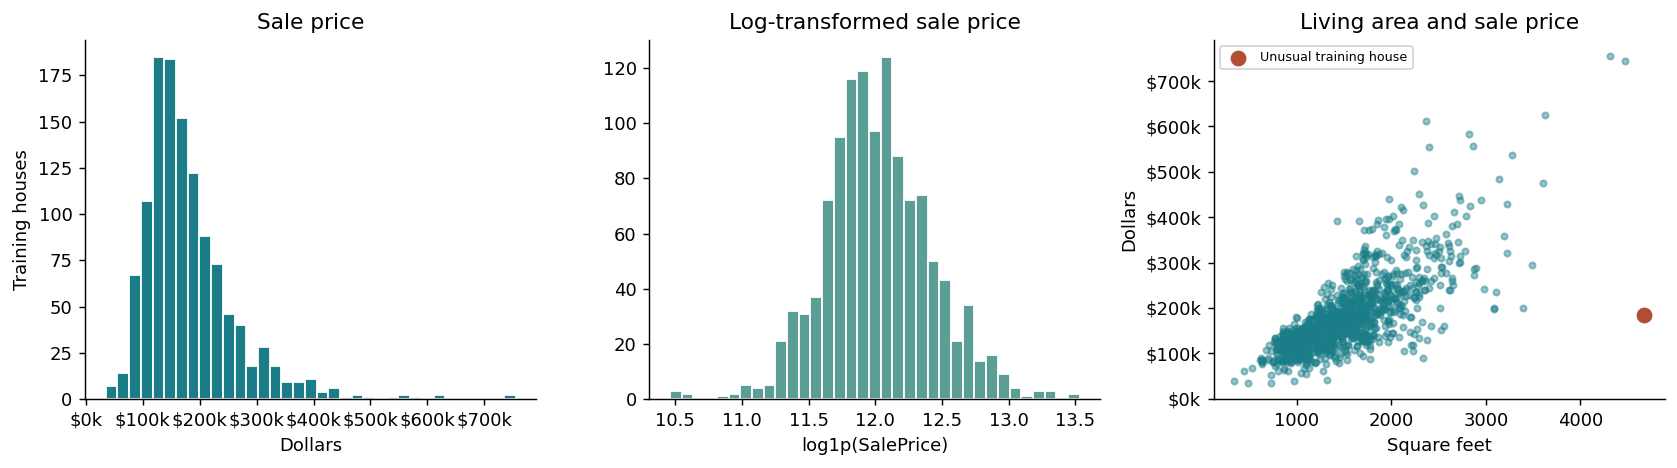

,Id,Neighborhood,GrLivArea,SalePrice
523,524,Edwards,4676,184750


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
axes[0].hist(y, bins=35, color="#1a7d88", edgecolor="white")
axes[0].set(title="Sale price", xlabel="Dollars", ylabel="Training houses")
axes[1].hist(np.log1p(y), bins=35, color="#5b9e96", edgecolor="white")
axes[1].set(title="Log-transformed sale price", xlabel="log1p(SalePrice)")
atypical = (train.GrLivArea > 4000) & (train.SalePrice < 300000)
axes[2].scatter(train.GrLivArea, y, s=12, alpha=.45, color="#1a7d88")
axes[2].scatter(train.loc[atypical, "GrLivArea"], y[atypical], s=60,
                color="#b34e34", label="Unusual training house")
axes[2].set(title="Living area and sale price", xlabel="Square feet", ylabel="Dollars")
axes[2].legend(fontsize=7)
# Short currency labels keep the plots readable.
price_label = FuncFormatter(lambda value, _: f"${value / 1000:,.0f}k")
axes[0].xaxis.set_major_formatter(price_label)
axes[2].yaxis.set_major_formatter(price_label)
fig.tight_layout()
plt.show()
display(train.loc[atypical, ["Id", "Neighborhood", "GrLivArea", "SalePrice"]])


## 3. Preparing the features

A blank value can mean different things. For example, a missing pool-quality value often means there is no pool. The code uses zero for absent quality/size features where that makes sense. Other numeric gaps use training medians. Missing lot frontage uses the median for that neighborhood.

Quality grades are put in order from poor to excellent. Other categories are turned into separate columns for SVR and Elastic Net. LightGBM handles category columns directly. SVR and Elastic Net also use scaled numeric inputs.

We added a few summaries: total floor area, finished area, bathrooms, porch space, house age and time since remodeling. Some features combine quality with size or age. These calculations use house features only.

Imputation, encoding and scaling are fitted on each training fold, then applied to its validation rows.

In [4]:
missing = train.isna().sum().sort_values(ascending=False)
display(pd.DataFrame({"missing_rows": missing, "percent": 100 * missing / len(train)}).head(12))
feature_example = HouseFeatures(engineered=True, interactions=True).fit_transform(X)
print("Original input features excluding Id:", X.shape[1] - 1)
print("Features before one-hot encoding:", feature_example.shape[1])
display(feature_example[["TotalSF", "FinishedSF", "TotalBath", "HouseAge",
                         "RemodelAge", "HasGarage", "QualLiving"]].head())


Original input features excluding Id: 79
Features before one-hot encoding: 105


,missing_rows,percent
PoolQC,1196,99.666667
MiscFeature,1153,96.083333
Alley,1125,93.750000
Fence,973,81.083333
MasVnrType,717,59.750000
FireplaceQu,564,47.000000
LotFrontage,210,17.500000
GarageQual,67,5.583333
GarageFinish,67,5.583333
GarageType,67,5.583333


,TotalSF,FinishedSF,TotalBath,HouseAge,RemodelAge,HasGarage,QualLiving
0,2566,2416,3.5,5,5,1,52.113833
1,2524,2240,2.5,31,31,1,42.847471
2,2706,2272,3.5,7,6,1,52.418055
3,2473,1933,2.0,91,36,1,52.142413
4,3343,2853,3.5,8,8,1,61.566064


## 4. Comparing models

We split the training data into five parts. For each part, a model trains on the other four and predicts the held-out rows. This gives every house a prediction from a model that did not train on it. These are called **out-of-fold (OOF) predictions**.

The same splits are used for all models. Price bands help spread cheaper and more expensive houses across the folds.

The saved search covers **90 model setups**. Seven model families were checked on two more sets of folds, for **520 training fits** in that search. Below, we rerun the baselines and the saved final settings.

The first baseline predicts the training mean for every house. Ridge regression is a more useful starting point because it uses the house features.

In [5]:
SEED = 20261103
# Keep the price ranges reasonably balanced across folds.
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(
    X, pd.qcut(y, 10, labels=False, duplicates="drop")))

dummy_oof = np.empty(len(y))
ridge_oof = np.empty(len(y))
for training, validation in folds:
    dummy = DummyRegressor(strategy="mean").fit(X.iloc[training], y[training])
    dummy_oof[validation] = dummy.predict(X.iloc[validation])
    ridge = make_model({"family": "ridge", "alpha": 12, "target": "log", "interactions": True})
    ridge.fit(X.iloc[training], y[training])
    ridge_oof[validation] = ridge.predict(X.iloc[validation])

baseline_scores = pd.DataFrame({
    "model": ["Mean-price baseline", "Ridge with feature preparation"],
    "OOF RMSE ($)": [root_mean_squared_error(y, dummy_oof), root_mean_squared_error(y, ridge_oof)]})
display(baseline_scores.round(2))


,model,OOF RMSE ($)
0,Mean-price baseline,81052.77
1,Ridge with feature preparation,27150.93


In [6]:
search = pd.read_csv(ROOT / "results/all_model_scores.csv")
search_configs = json.loads((ROOT / "experiments/screen_configurations.json").read_text())
confirmation = json.loads((ROOT / "results/confirmation_results.json").read_text())
assert len(search_configs) == len(search) == 90
assert len(confirmation) == 14
print("Search fits:", len(search_configs) * 5 + len(confirmation) * 5)

# Show the best setup from each family. Full trial details are in results/.
family_names = {
    "ridge": "Ridge", "elastic": "Elastic Net", "svr": "SVR",
    "krr": "Kernel Ridge", "gbr": "Gradient Boosting", "extra": "Extra Trees",
    "forest": "Random Forest", "hist": "Histogram Gradient Boosting",
    "catboost": "CatBoost", "lightgbm": "LightGBM",
}
best_by_family = search.loc[search.groupby("family")["guarded_rmse"].idxmin()]
summary = best_by_family[["family", "guarded_rmse"]].sort_values("guarded_rmse").copy()
summary["family"] = summary["family"].map(family_names)
summary.columns = ["Model family", "Validation RMSE ($)"]
display(summary.reset_index(drop=True).round(2))
print("Scores include the similar-house rule explained in the next section.")


Search fits: 520
Scores include the similar-house rule explained in the next section.


,Model family,Validation RMSE ($)
0,SVR,20985.04
1,Elastic Net,21410.95
2,Ridge,21483.74
3,Kernel Ridge,23332.04
4,CatBoost,26845.07
5,LightGBM,27142.02
6,Gradient Boosting,27399.46
7,Histogram Gradient Boosting,27711.83
8,Extra Trees,27936.75
9,Random Forest,30003.96


## 5. The final model

The final prediction is a weighted average of three models:

| Model | Why include it? |
| :--- | :--- |
| SVR | Fits patterns that a straight-line model can miss |
| Elastic Net | A regularized linear model using the prepared features |
| LightGBM | Uses boosted trees to capture feature interactions |

All three fit log prices. We convert each prediction back to dollars, then take the weighted average. The weights were chosen from the training validation predictions.

For a house larger than every row in the current training set, the main version uses the mean price of three similar sales in the same neighborhood. Similarity is based on living area, basement area, overall quality and year built. Area values are logged and the distance inputs are standardized. The same rule is tested inside each validation fold.

We also keep an alternative using the closest single sale. There are very few houses this large, so this part needs caution: it could underestimate a genuinely expensive large house.

In [7]:
selection = json.loads((ROOT / "config/final_model.json").read_text())
model_rows = []
for component in selection["models"]:
    settings = component["spec"]
    family = settings["family"]
    if family == "svr":
        details = f"RBF kernel; C={settings['C']}, gamma={settings['gamma']}, epsilon={settings['epsilon']}"
    elif family == "elastic":
        details = f"alpha={settings['alpha']}, l1_ratio={settings['l1_ratio']}"
    else:
        details = f"{settings['n_estimators']} trees; {settings['num_leaves']} leaves; learning rate={settings['learning_rate']}"
    model_rows.append({"Model": family_names[family],
                       "Weight": f"{component['weight']:.2%}", "Main settings": details})
display(pd.DataFrame(model_rows))
print("Similar sales used by the main version:", selection["guard_k"])


Similar sales used by the main version: 3


,Model,Weight,Main settings
0,SVR,57.17%,"RBF kernel; C=100, gamma=0.0002, epsilon=0.008"
1,Elastic Net,32.74%,"alpha=0.0002, l1_ratio=0.8"
2,LightGBM,10.09%,1800 trees; 8 leaves; learning rate=0.025


## 6. Check the saved settings

This cell fits the final models again using the first set of five folds. Each model sees only its training rows. The weights stay fixed at the values selected earlier.

We compare errors before and after the similar-house rule. The final check confirms that the new result matches the saved validation score.

MAE is shown too. It is the average absolute price error in dollars.

In [8]:
raw_oof = np.empty(len(y))
final_oof = np.empty(len(y))
nearest_oof = np.empty(len(y))
fold_results = []
for fold_number, (training, validation) in enumerate(folds, start=1):
    parts = []
    for component in selection["models"]:
        # Apply the row filter only to this fold's training data.
        keep = training_mask(X.iloc[training], y[training], component["policy"])
        model = make_model(component["spec"])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", UserWarning)
            model.fit(X.iloc[training].loc[keep], y[training][keep])
            prediction = np.maximum(1, model.predict(X.iloc[validation]))
        parts.append(component["weight"] * prediction)
    blended = np.sum(parts, axis=0)
    raw_oof[validation] = blended
    final_oof[validation] = comparable_guard(
        X.iloc[training], y[training], X.iloc[validation], blended, k=selection["guard_k"])
    nearest_oof[validation] = comparable_guard(
        X.iloc[training], y[training], X.iloc[validation], blended, k=1)
    fold_results.append({"fold": fold_number,
                         "RMSE before similar-house rule": root_mean_squared_error(y[validation], blended),
                         "RMSE after similar-house rule": root_mean_squared_error(y[validation], final_oof[validation])})

display(pd.DataFrame(fold_results).round(2))
recomputed = root_mean_squared_error(y, final_oof)
print(f"Pooled five-fold RMSE: ${recomputed:,.2f}")
print(f"Pooled five-fold MAE:  ${mean_absolute_error(y, final_oof):,.2f}")
assert np.isclose(recomputed, selection["seed_rmse"][0], atol=.05)
print("This matches the saved validation result.")


Pooled five-fold RMSE: $20,890.09
Pooled five-fold MAE:  $12,809.73
This matches the saved validation result.


,fold,RMSE before similar-house rule,RMSE after similar-house rule
0,1,19942.82,19942.82
1,2,20408.84,20408.84
2,3,19853.04,19853.04
3,4,42000.32,17788.26
4,5,25635.45,25635.45


,model,OOF RMSE ($)
0,Mean-price baseline,81052.77
1,Ridge with feature preparation,27150.93
2,Ensemble before fallback,26942.84
3,Ensemble with 3 comparables,20890.09
4,Ensemble with 1 comparable,21249.40


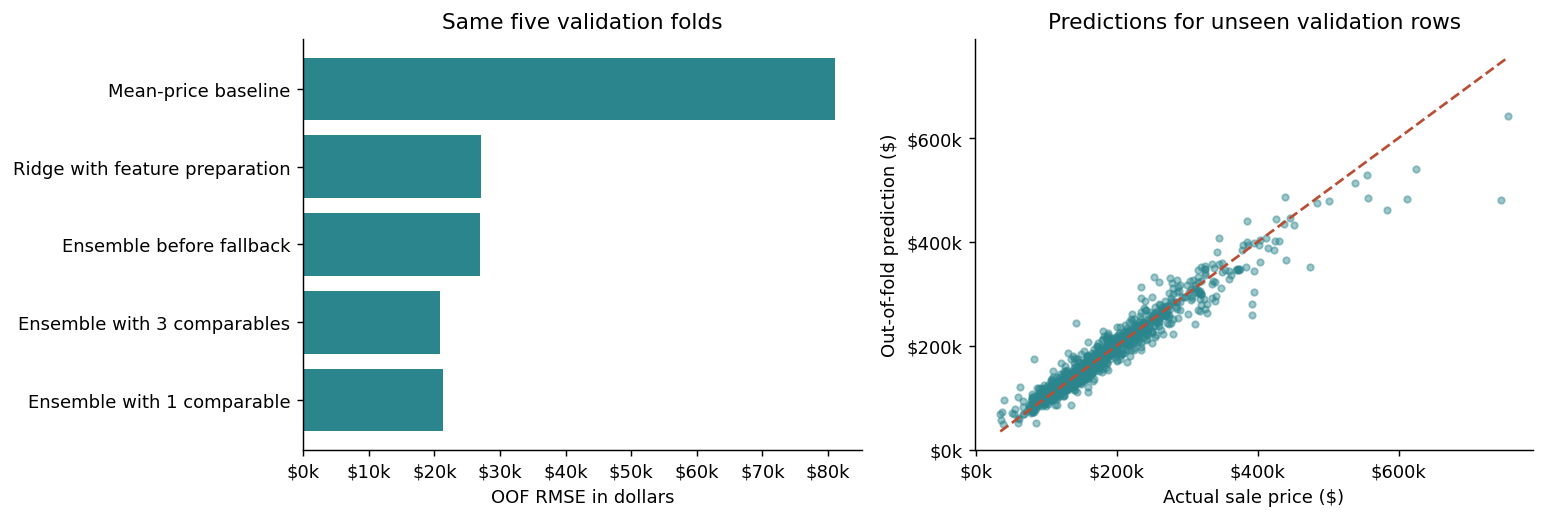

In [9]:
comparison = pd.concat([baseline_scores, pd.DataFrame({
    "model": ["Ensemble before fallback", "Ensemble with 3 comparables", "Ensemble with 1 comparable"],
    "OOF RMSE ($)": [root_mean_squared_error(y, raw_oof), recomputed,
                       root_mean_squared_error(y, nearest_oof)]})], ignore_index=True)
display(comparison.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.1))
axes[0].barh(comparison["model"], comparison["OOF RMSE ($)"], color="#2b858d")
axes[0].invert_yaxis()
axes[0].set(xlabel="OOF RMSE in dollars", title="Same five validation folds")
axes[1].scatter(y, final_oof, s=13, alpha=.45, color="#2b858d")
limits = [min(y.min(), final_oof.min()), max(y.max(), final_oof.max())]
axes[1].plot(limits, limits, "--", color="#b94e35")
axes[1].set(xlabel="Actual sale price ($)", ylabel="Out-of-fold prediction ($)",
            title="Predictions for unseen validation rows")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value / 1000:,.0f}k"))
for axis in [axes[1].xaxis, axes[1].yaxis]:
    axis.set_major_locator(MaxNLocator(5))
    axis.set_major_formatter(FuncFormatter(lambda value, _: f"${value / 1000:,.0f}k"))
fig.tight_layout()
plt.show()


## 7. Check the other splits

The three validation runs gave RMSEs of about **$20,890**, **$20,666** and **$20,478**. Pooling all their predictions gives **$20,678.78**.

We used these predictions to choose the weights, so this score may look better than it would on a fresh dataset. The saved results also show what happens when weights chosen on one run are used on the other runs.

A few expensive or unusual houses can have a large effect on dollar RMSE. That is one reason to check several splits rather than rely on a single score.

In [10]:
display(pd.DataFrame({"partition_seed": selection["seeds"],
                      "saved_OOF_RMSE": selection["seed_rmse"]}).round(2))
print("Repeated out-of-fold RMSE:", round(selection["repeated_oof_rmse"], 2))
checks = []
for item in selection["cross_seed_weight_checks"]:
    for assessment_seed, score in item["assessment_rmse"].items():
        checks.append({"weight_fit_seed": item["weight_fit_seed"],
                       "assessment_seed": assessment_seed, "RMSE": score})
display(pd.DataFrame(checks).round(2))


Repeated out-of-fold RMSE: 20678.78


,partition_seed,saved_OOF_RMSE
0,20261103,20890.09
1,131,20666.03
2,271,20478.16


,weight_fit_seed,assessment_seed,RMSE
0,20261103,131,21118.39
1,20261103,271,20798.39
2,131,20261103,21234.90
3,131,271,20372.75
4,271,20261103,21449.77
5,271,131,20630.67


## 8. Create the submission files

Now the saved models are fitted on the full training data. `train.py` writes three versions: the main blend with three similar sales, the one-sale alternative, and an alternative without LightGBM.

The script reads `train.csv`, `test.csv` and `sample_soln.csv`. Only the sample file's IDs are used. It does not read the answer file.

We check that each output has 260 rows, unique IDs, positive finite prices and exactly two columns: `Id` and `SalePrice`.

In [11]:
candidates, audit = generate(ROOT / "data", ROOT / "outputs")
for filename in candidates:
    submitted = pd.read_csv(ROOT / "outputs" / filename)
    assert submitted.columns.tolist() == ["Id", "SalePrice"]
    assert submitted.Id.tolist() == template.Id.tolist()
    assert len(submitted) == 260 and submitted.Id.is_unique
    assert np.isfinite(submitted.SalePrice).all() and (submitted.SalePrice > 0).all()
display(pd.read_csv(ROOT / "outputs/submission_model.csv").head())
print("All generated CSVs passed the submission-format checks.")
print("The output folder also contains a record of the settings and file checks.")


Fitted svr2_C100_g0.0002 (57.17%)
Fitted elastic_a0.0002 (32.74%)
Fitted lgb_log_m1_l8 (10.09%)
All generated CSVs passed the submission-format checks.
The output folder also contains a record of the settings and file checks.


,Id,SalePrice
0,0,100732.133620
1,1,195779.274994
2,2,139198.076846
3,3,202898.346939
4,4,151406.106907


## 9. Compare with the provided answers

The download also included `solns.csv`, which contains test sale prices. We noticed it while checking the files. Those values were kept out of model fitting, parameter comparisons and weight selection. After the model settings were fixed, they were used for the comparison below.

Because the answers were available and inspected, this is **a comparison with the provided file**, not an independent blind test.

This cell is optional. If `solns.csv` is in `data/`, it calculates the scores. Otherwise it shows the saved comparison. Across all 260 answers, the main version scored about **$19,504 RMSE**, and the one-sale alternative about **$19,301**.

In [12]:
reference_path = ROOT / "data/solns.csv"
if reference_path.exists():
    reference = pd.read_csv(reference_path)[["Id", "SalePrice"]]
    audit_rows = []
    for filename in candidates:
        prediction = pd.read_csv(ROOT / "outputs" / filename)
        aligned = reference.merge(prediction, on="Id", suffixes=("_true", "_pred"),
                                  validate="one_to_one")
        assert len(aligned) == 260
        audit_rows.append({"file": filename,
                           "RMSE against provided answers ($)": root_mean_squared_error(
                               aligned.SalePrice_true, aligned.SalePrice_pred)})
    display(pd.DataFrame(audit_rows).round(2))
else:
    print("No optional answer file found. Showing the saved comparison.")
    recorded = pd.read_csv(ROOT / "results/provided_reference_audit.csv")
    display(recorded[recorded.file.isin(candidates)][["file", "rmse_all_260"]].round(2))


No optional answer file found. Showing the saved comparison.


,file,rmse_all_260
0,submission_model.csv,19503.79
1,submission_nearest_comparable.csv,19300.77
2,submission_sklearn_only.csv,19636.03


## 10. Results and takeaways

The reported Kaggle score for the model-generated v3 submission was **14,352.97895**. A later submission, v4, used the supplied answer values directly and scored **0.00000**. That zero came from the answer file. The model code in this notebook did not produce it.

Kaggle scores a hidden part of the test data. We cannot calculate that public score locally without knowing which rows were used. The notebook exports both model candidates; the file renamed v3 still needs to be matched to its saved CSV to confirm which one was uploaded.

The blend improved on the baselines in validation. The unusual-house checks also helped, but there are too few extreme examples to be confident about that rule for every future house. The validation and reference scores should be read with those limits in mind.

The repository includes the code, settings and experiment records needed to follow the work. ChatGPT helped with the code, experiments and editing.

In [13]:
display(pd.DataFrame([
    {"submission": "v1", "public_RMSE": 20204.14995, "source": "Earlier trained-model submission"},
    {"submission": "v3", "public_RMSE": 14352.97895, "source": "Reported model-generated submission"},
    {"submission": "v4", "public_RMSE": 0.0, "source": "Provided answers submitted directly"},
]))
print("Public scores above are from the team's Kaggle submission history.")
print("The public/private test split is unknown; these public scores are not locally recomputed.")


Public scores above are from the team's Kaggle submission history.
The public/private test split is unknown; these public scores are not locally recomputed.


,submission,public_RMSE,source
0,v1,20204.14995,Earlier trained-model submission
1,v3,14352.97895,Reported model-generated submission
2,v4,0.00000,Provided answers submitted directly
